<a href="https://colab.research.google.com/github/contreras-juan/procesamiento_lenguaje_natural/blob/main/Cuadernos/16_Atencion_Transformers.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<h1 style="color: #FECB05; text-align: center;">Atención y Transformers</h1>

<h2 style="color: #007ACC;">Autores</h2>

- [Juan Felipe Contreras Alcívar](https://www.linkedin.com/in/juanf-contreras/)

---

<h2 style="color: #007ACC;">Tabla de contenido</h2>

- [<span style="color: #005C99;">Introducción</span>](#introduccion)
- [<span style="color: #005C99;">Mecanismo de atención</span>](#mecanismo-de-atencion)
- [<span style="color: #005C99;">Self-attention</span>](#self-attention)
- [<span style="color: #005C99;">Multi-head attention</span>](#multi-head-attention)
- [<span style="color: #005C99;">Codificación posicional</span>](#codificacion-posicional)
- [<span style="color: #005C99;">Arquitectura Transformer</span>](#arquitectura-transformer)
- [<span style="color: #005C99;">Un Transformer para clasificar reseñas</span>](#un-transformer-para-clasificar-resenas)
- [<span style="color: #005C99;">Referencias</span>](#referencias)

---

<h2 style="color: #007ACC;">Instalación de librerías</h2>

Ejecuta esta celda si trabajas en Google Colab o en un entorno nuevo.

In [1]:
# Instalación de librerías necesarias para esta sesión
# (útil en Google Colab o en un entorno nuevo)
%pip install -q numpy pandas matplotlib seaborn tensorflow datasets

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"  # oculta mensajes informativos de TensorFlow

import re
import string
import time
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

SEED = 42
keras.utils.set_random_seed(SEED)  # fija las semillas de Python, NumPy y TensorFlow
import seaborn as sns

<a id="introduccion"></a>
<h2 style="color: #007ACC;">Introducción</h2>

En el cuaderno 14, el codificador de un Seq2Seq comprimía toda la oración de origen en **un solo vector** de tamaño fijo, y la calidad de la traducción (BLEU) caía con la longitud de la oración. En el cuaderno 13 vimos además que las RNN procesan el texto **palabra por palabra**, lo que impide paralelizar el entrenamiento.

El **mecanismo de atención** resuelve los dos problemas:

1. **Bahdanau et al. (2015)** propusieron que el decodificador, en cada paso, **consultara todos los estados** del codificador y los combinara con pesos que dependen de lo que está generando. Ya no hay un único vector cuello de botella.
2. **Vaswani et al. (2017)**, en *Attention Is All You Need*, eliminaron por completo la recurrencia: el **Transformer** procesa todas las palabras en paralelo y relaciona cada palabra con todas las demás mediante atención.

El Transformer es la base de BERT, GPT, T5 y de todos los grandes modelos de lenguaje actuales. En este cuaderno construimos sus piezas una por una (atención, self-attention, multi-head attention, codificación posicional y el bloque completo), primero en NumPy y luego en Keras, y entrenamos un Transformer pequeño para clasificar reseñas.

<a id="mecanismo-de-atencion"></a>
<h2 style="color: #007ACC;">Mecanismo de atención</h2>

La atención se entiende mejor como una **búsqueda suave en un diccionario**. En un diccionario de Python, una **consulta** (*query*) se compara con cada **clave** (*key*) y se devuelve el **valor** (*value*) de la clave que coincide exactamente. En la atención:

- la consulta se compara con **todas** las claves mediante una medida de similitud (el producto punto);
- las similitudes se convierten en **pesos** que suman 1 con una softmax;
- se devuelve el **promedio ponderado** de los valores.

$$\text{Atención}(\mathbf{q}, K, V) = \sum_i \alpha_i \mathbf{v}_i, \qquad \alpha_i = \text{softmax}_i\left(\frac{\mathbf{q} \cdot \mathbf{k}_i}{\sqrt{d_k}}\right)$$

En la traducción con atención, la consulta es el estado actual del decodificador y las claves y los valores son los estados del codificador para cada palabra de origen. Al generar *"dog"*, el decodificador "mira" sobre todo a *"perro"*.

```text
codificador:   El      perro    duerme
               h1       h2       h3        ← claves y valores
               │        │        │
pesos α:      0.05     0.90     0.05      ← softmax(q · k_i)
               └────────┼────────┘
                        ▼
          contexto = Σ α_i h_i   →  decodificador genera "dog"
```

Implementemos la **atención de producto punto escalado** con matrices: con $n$ consultas a la vez, $Q \in \mathbb{R}^{n \times d_k}$, $K \in \mathbb{R}^{m \times d_k}$ y $V \in \mathbb{R}^{m \times d_v}$,

$$\text{Atención}(Q, K, V) = \text{softmax}\left(\frac{Q K^\top}{\sqrt{d_k}}\right) V$$

In [3]:
def softmax(x, eje=-1):
    x = x - x.max(axis=eje, keepdims=True)  # estabilidad numérica
    e = np.exp(x)
    return e / e.sum(axis=eje, keepdims=True)


def atencion(Q, K, V, mascara=None):
    """Q: (n, d_k), K: (m, d_k), V: (m, d_v). mascara: (n, m) booleana, True = se puede atender."""
    puntajes = Q @ K.T / np.sqrt(K.shape[-1])
    if mascara is not None:
        puntajes = np.where(mascara, puntajes, -1e9)
    pesos = softmax(puntajes)
    return pesos @ V, pesos


# Un "diccionario" con 3 entradas: las claves son casi ortogonales
K = np.array([[1.0, 0, 0, 0], [0, 1.0, 0, 0], [0, 0, 1.0, 0]]) * 4
V = np.array([[10.0, 0], [0, 10.0], [5.0, 5.0]])
q = np.array([[0, 1.0, 0, 0]]) * 4  # se parece a la segunda clave
salida, pesos = atencion(q, K, V)
print("pesos:", pesos.round(3), "→ salida:", salida.round(2))

q_mezcla = np.array([[2.0, 2.0, 0, 0]])  # a medio camino entre la primera y la segunda clave
salida, pesos = atencion(q_mezcla, K, V)
print("pesos:", pesos.round(3), "→ salida:", salida.round(2))

pesos: [[0.    0.999 0.   ]] → salida: [[0.01 9.99]]
pesos: [[0.495 0.495 0.009]] → salida: [[5. 5.]]


Con una consulta parecida a una sola clave, la atención se comporta casi como un diccionario y devuelve su valor. Con una consulta ambigua, devuelve una **mezcla** de los valores. A diferencia del diccionario, la operación es **diferenciable**: la red puede aprender qué consultar.

**¿Por qué dividir por $\sqrt{d_k}$?** Si las componentes de $\mathbf{q}$ y $\mathbf{k}$ son independientes con varianza 1, el producto punto tiene varianza $d_k$. Con dimensiones grandes, los puntajes son muy grandes, la softmax se **satura** (pone casi todo el peso en una sola clave) y sus gradientes se anulan. Midámoslo con la entropía de los pesos (máxima, $\log m$, si son uniformes; 0 si toda la masa está en una clave):

In [4]:
rng = np.random.default_rng(SEED)
m = 20
filas = []
for d_k in [4, 16, 64, 256, 1024]:
    Q, K = rng.normal(size=(500, d_k)), rng.normal(size=(m, d_k))
    for escalar in [False, True]:
        puntajes = Q @ K.T / (np.sqrt(d_k) if escalar else 1)
        p = softmax(puntajes)
        entropia = -(p * np.log(p + 1e-12)).sum(axis=1).mean()
        filas.append({"d_k": d_k, "escalado": "con √d_k" if escalar else "sin escalar",
                      "entropía media": entropia, "peso máximo medio": p.max(axis=1).mean()})
print(f"Entropía máxima (pesos uniformes sobre {m} claves): {np.log(m):.2f}")
pd.DataFrame(filas).pivot(index="d_k", columns="escalado", values=["entropía media", "peso máximo medio"]).round(3)

Entropía máxima (pesos uniformes sobre 20 claves): 3.00


entropía media             peso máximo medio            
escalado       con √d_k sin escalar          con √d_k sin escalar
d_k                                                              
4                 2.576       1.880             0.215       0.418
16                2.592       1.008             0.208       0.656
64                2.571       0.435             0.214       0.835
256               2.570       0.221             0.213       0.912
1024              2.571       0.092             0.215       0.963

Sin escalar, a partir de $d_k = 64$ la softmax ya pone casi todo el peso en una sola clave. Con el escalado, la distribución de los pesos no depende de la dimensión.

<a id="self-attention"></a>
<h2 style="color: #007ACC;">Self-attention</h2>

En la **self-attention** (autoatención), las consultas, claves y valores salen **de la misma secuencia**. Cada palabra calcula su nueva representación consultando a todas las palabras de la oración, incluida ella misma. Las tres proyecciones son matrices aprendidas:

$$Q = X W^Q, \qquad K = X W^K, \qquad V = X W^V$$

Así, en *"el banco del parque estaba recién pintado"*, la representación de *banco* puede incorporar información de *parque* (y alejarse del sentido financiero). Esta es la idea de los **embeddings contextuales**: a diferencia de Word2Vec, la representación de una palabra depende de la oración.

Comparada con una RNN:

| | RNN | Self-attention |
|---|---|---|
| Operaciones secuenciales | $O(T)$ | $O(1)$: todo en paralelo |
| Distancia máxima entre dos palabras | $T$ pasos | 1 paso |
| Costo por capa | $O(T \cdot d^2)$ | $O(T^2 \cdot d)$ |

El precio es el costo **cuadrático** en la longitud: cada palabra se compara con todas. Por eso los Transformers tienen una longitud máxima de contexto.

Hay dos **máscaras** importantes:

- **De relleno** (*padding mask*): ninguna palabra debe atender a las posiciones de relleno.
- **Causal** (*look-ahead mask*): en un modelo que genera texto de izquierda a derecha (GPT, el decodificador de un Transformer), la palabra $t$ solo puede atender a las palabras $1, \dots, t$; si viera las siguientes, el entrenamiento sería trampa.

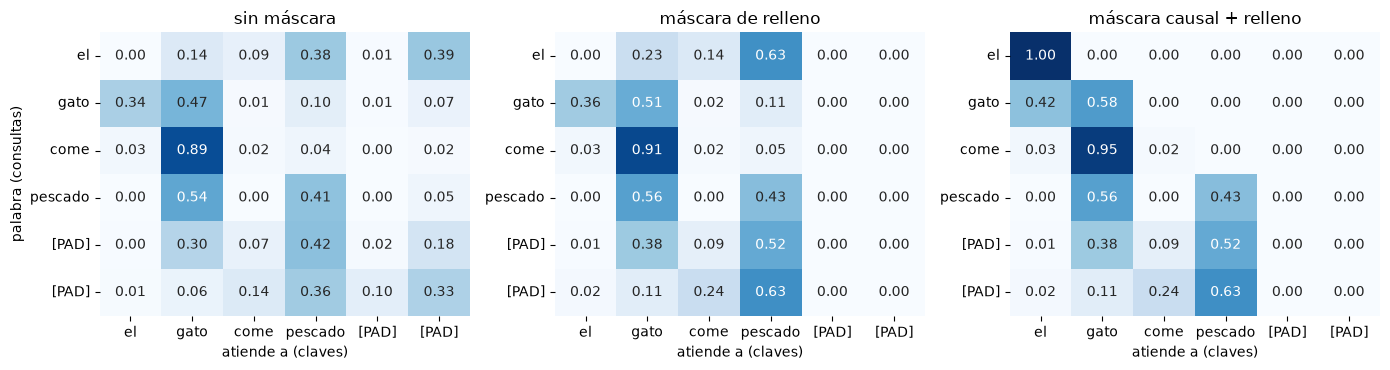

In [5]:
rng = np.random.default_rng(SEED)
palabras = ["el", "gato", "come", "pescado", "[PAD]", "[PAD]"]
T, d_modelo, d_k = len(palabras), 8, 4
X = rng.normal(size=(T, d_modelo))
W_Q, W_K, W_V = (rng.normal(size=(d_modelo, d_k)) for _ in range(3))
Q, K, V = X @ W_Q, X @ W_K, X @ W_V

reales = np.array([p != "[PAD]" for p in palabras])
mascara_relleno = np.broadcast_to(reales, (T, T))  # nadie atiende al relleno
mascara_causal = np.tril(np.ones((T, T), dtype=bool)) & mascara_relleno

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, (titulo, mascara) in zip(axes, [("sin máscara", None), ("máscara de relleno", mascara_relleno),
                                        ("máscara causal + relleno", mascara_causal)]):
    _, pesos = atencion(Q, K, V, mascara)
    sns.heatmap(pesos, annot=True, fmt=".2f", cmap="Blues", cbar=False, ax=ax,
                xticklabels=palabras, yticklabels=palabras, vmin=0, vmax=1)
    ax.set_title(titulo)
    ax.set_xlabel("atiende a (claves)")
axes[0].set_ylabel("palabra (consultas)")
plt.tight_layout()
plt.show()

Cada fila es una distribución de pesos (suma 1). Con la máscara causal, la matriz es **triangular inferior**: *gato* solo ve *el* y *gato*. Los pesos de estas matrices son aleatorios porque $W^Q$, $W^K$ y $W^V$ no se han entrenado. Las filas del relleno no importan, porque sus salidas se descartan.

<a id="multi-head-attention"></a>
<h2 style="color: #007ACC;">Multi-head attention</h2>

Una sola atención produce un único promedio ponderado por palabra. Pero una palabra puede necesitar información de varias otras por razones distintas: el sujeto de un verbo, el sustantivo al que se refiere un pronombre, la palabra negada... La **multi-head attention** ejecuta $h$ atenciones en paralelo, cada una con sus propias proyecciones de dimensión $d_k = d_{\text{modelo}} / h$, y concatena los resultados:

$$\text{MultiHead}(X) = \text{Concat}(\text{cabeza}_1, \dots, \text{cabeza}_h)\, W^O, \qquad \text{cabeza}_i = \text{Atención}(X W_i^Q, X W_i^K, X W_i^V)$$

El costo total es similar al de una sola atención de dimensión completa. Implementémosla en NumPy y comprobemos que coincide con la capa `MultiHeadAttention` de Keras, copiando sus pesos:

In [6]:
def multi_head(X, pesos_capa, mascara=None):
    """Réplica en NumPy de keras.layers.MultiHeadAttention (self-attention)."""
    Wq, bq, Wk, bk, Wv, bv, Wo, bo = pesos_capa  # Wq: (d_modelo, h, d_k); Wo: (h, d_k, d_modelo)
    cabezas = []
    for i in range(Wq.shape[1]):
        Q = X @ Wq[:, i] + bq[i]
        K = X @ Wk[:, i] + bk[i]
        V = X @ Wv[:, i] + bv[i]
        cabezas.append(atencion(Q, K, V, mascara)[0])
    concatenado = np.concatenate(cabezas, axis=-1)                # (T, h · d_k)
    return concatenado @ Wo.reshape(-1, Wo.shape[-1]) + bo         # (T, d_modelo)


h, d_modelo = 4, 16
X = rng.normal(size=(6, d_modelo)).astype("float32")
mha = layers.MultiHeadAttention(num_heads=h, key_dim=d_modelo // h)
salida_keras = mha(X[None], X[None], attention_mask=mascara_causal[None])[0].numpy()

print("Formas de los pesos:", [w.shape for w in mha.get_weights()])
print("¿Coinciden NumPy y Keras?", np.allclose(multi_head(X, mha.get_weights(), mascara_causal), salida_keras, atol=1e-4))

Formas de los pesos: [(16, 4, 4), (4, 4), (16, 4, 4), (4, 4), (16, 4, 4), (4, 4), (4, 4, 16), (16,)]
¿Coinciden NumPy y Keras? True


<a id="codificacion-posicional"></a>
<h2 style="color: #007ACC;">Codificación posicional</h2>

La self-attention tiene una propiedad incómoda para el lenguaje: **no sabe en qué orden están las palabras**. Si permutamos la entrada, la salida se permuta de la misma forma (es *equivariante a permutaciones*): para ella, *"el perro muerde al hombre"* y *"el hombre muerde al perro"* son el mismo conjunto de palabras.

In [7]:
permutacion = np.array([3, 1, 4, 0, 5, 2])
salida = mha(X[None], X[None])[0].numpy()
salida_permutada = mha(X[permutacion][None], X[permutacion][None])[0].numpy()
print("¿atención(X permutada) = atención(X) permutada?", np.allclose(salida_permutada, salida[permutacion], atol=1e-5))

¿atención(X permutada) = atención(X) permutada? True


La solución es **sumar a cada embedding un vector que codifique su posición**. El Transformer original usa senos y cosenos de distintas frecuencias:

$$PE_{(pos,\, 2i)} = \sin\left(\frac{pos}{10000^{2i/d}}\right), \qquad PE_{(pos,\, 2i+1)} = \cos\left(\frac{pos}{10000^{2i/d}}\right)$$

Cada par de dimensiones es un "reloj" que gira a una velocidad distinta: las primeras dimensiones cambian rápido entre posiciones vecinas y las últimas muy lento, como los dígitos de un número. Además, $PE_{pos+k}$ es una transformación lineal (una rotación) de $PE_{pos}$, lo que facilita que el modelo aprenda posiciones **relativas**.

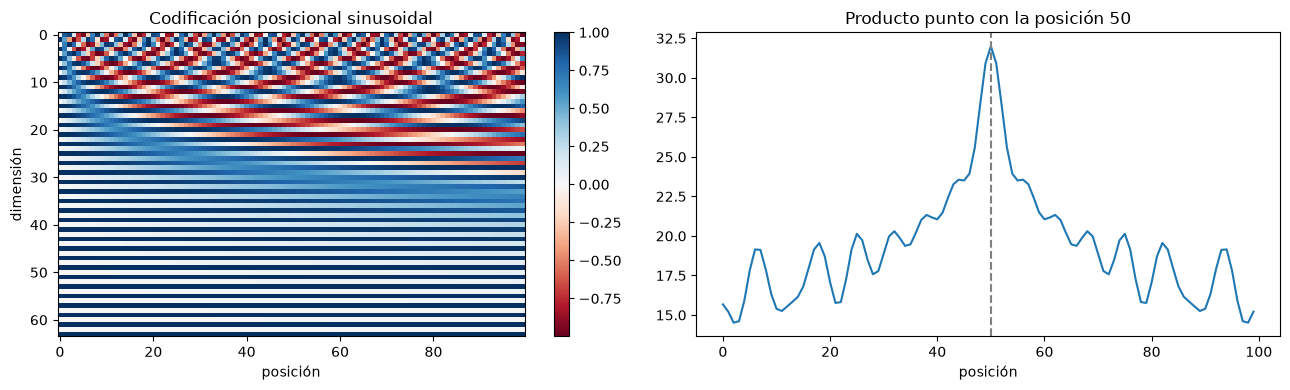

In [8]:
def codificacion_posicional(longitud, d):
    pos = np.arange(longitud)[:, None]
    i = np.arange(0, d, 2)[None, :]
    angulos = pos / 10000 ** (i / d)
    pe = np.zeros((longitud, d))
    pe[:, 0::2], pe[:, 1::2] = np.sin(angulos), np.cos(angulos)
    return pe


PE = codificacion_posicional(100, 64)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
im = axes[0].imshow(PE.T, aspect="auto", cmap="RdBu")
axes[0].set_xlabel("posición")
axes[0].set_ylabel("dimensión")
axes[0].set_title("Codificación posicional sinusoidal")
fig.colorbar(im, ax=axes[0])
similitud = PE @ PE[50]
axes[1].plot(similitud)
axes[1].axvline(50, color="gray", ls="--")
axes[1].set_xlabel("posición")
axes[1].set_title("Producto punto con la posición 50")
plt.tight_layout()
plt.show()

El producto punto entre codificaciones es máximo en la misma posición y decae con la distancia, así que la atención puede distinguir palabras cercanas de lejanas.

Otras opciones:

- **Embeddings de posición aprendidos**: una tabla de `longitud_máxima × d` que se entrena como cualquier embedding. La usan BERT y GPT-2, y es la que usaremos en Keras.
- **Codificaciones relativas y rotatorias** (RoPE, Su et al., 2021): rotan las consultas y claves según la posición. Las usan la mayoría de los LLM actuales (Llama, Qwen, Mistral) porque generalizan mejor a contextos largos.

<a id="arquitectura-transformer"></a>
<h2 style="color: #007ACC;">Arquitectura Transformer</h2>

Un **bloque codificador** del Transformer combina la multi-head self-attention con una red *feed-forward* aplicada a cada posición por separado. Cada subcapa tiene una **conexión residual** y una **normalización de capa** (LayerNorm):

```text
entrada (T × d)
   │
   ├──────────────────┐
   ▼                  │
Multi-head            │
self-attention        │      las palabras intercambian información
   ▼                  │
Dropout ──── (+) ◄────┘      conexión residual
              ▼
          LayerNorm
              ├──────────────────┐
              ▼                  │
      Dense(d_ff, ReLU)          │      cada palabra se transforma por separado
      Dense(d)                   │
              ▼                  │
          Dropout ── (+) ◄───────┘
                      ▼
                  LayerNorm  →  salida (T × d)
```

- Las **conexiones residuales** permiten apilar decenas de bloques sin que el gradiente se desvanezca.
- La **red feed-forward** (normalmente $d_{ff} = 4d$) es donde está la mayor parte de los parámetros; se interpreta como una memoria de "hechos" asociados a patrones.

El **Transformer original** (para traducción) tiene dos pilas:

- un **codificador** de $N$ bloques como el anterior, que lee la oración de origen;
- un **decodificador** de $N$ bloques con tres subcapas: self-attention **causal** sobre lo ya generado, **atención cruzada** (las consultas vienen del decodificador y las claves y valores del codificador, exactamente la atención de Bahdanau) y la red feed-forward.

Los modelos actuales usan una de tres variantes:

| Variante | Atención | Preentrenamiento | Ejemplos | Uso típico |
|---|---|---|---|---|
| Solo codificador | Bidireccional | Predecir palabras enmascaradas | BERT, RoBERTa, BETO | Clasificación, NER, QA extractiva |
| Solo decodificador | Causal | Predecir la siguiente palabra | GPT, Llama, Qwen | Generación, asistentes conversacionales |
| Codificador-decodificador | Ambas + cruzada | Reconstruir texto corrupto | T5, BART, MarianMT | Traducción, resumen |

Implementemos el bloque codificador como una capa de Keras. La capa que suma embeddings de palabra y de posición propaga la **máscara** de relleno, y el bloque la convierte en una máscara de atención:

In [9]:
class EmbeddingPosicional(layers.Layer):
    """Embedding de palabras + embedding de posiciones aprendido."""

    def __init__(self, longitud, vocabulario, d, **kwargs):
        super().__init__(**kwargs)
        self.palabras = layers.Embedding(vocabulario, d, mask_zero=True)
        self.posiciones = layers.Embedding(longitud, d)

    def call(self, ids):
        posiciones = tf.range(tf.shape(ids)[-1])
        return self.palabras(ids) + self.posiciones(posiciones)

    def compute_mask(self, ids, mask=None):
        return self.palabras.compute_mask(ids)


class BloqueCodificador(layers.Layer):
    def __init__(self, d, cabezas, d_ff, dropout=0.1, **kwargs):
        super().__init__(**kwargs)
        self.supports_masking = True
        self.atencion = layers.MultiHeadAttention(num_heads=cabezas, key_dim=d // cabezas, dropout=dropout)
        self.ff = keras.Sequential([layers.Dense(d_ff, activation="relu"), layers.Dense(d)])
        self.norma1, self.norma2 = layers.LayerNormalization(), layers.LayerNormalization()
        self.drop1, self.drop2 = layers.Dropout(dropout), layers.Dropout(dropout)

    def call(self, x, mask=None, training=False):
        mascara_atencion = None if mask is None else mask[:, None, :]  # (lote, 1, T): nadie atiende al relleno
        a = self.atencion(x, x, attention_mask=mascara_atencion, training=training)
        x = self.norma1(x + self.drop1(a, training=training))
        return self.norma2(x + self.drop2(self.ff(x), training=training))


bloque = BloqueCodificador(d=64, cabezas=4, d_ff=256)
x = tf.random.normal((2, 10, 64))
print("Entrada:", x.shape, "→ salida:", bloque(x).shape)
print(f"Parámetros del bloque: {bloque.count_params():,} "
      f"(atención: {bloque.atencion.count_params():,}, feed-forward: {bloque.ff.count_params():,})")

Entrada: (2, 10, 64) → salida: (2, 10, 64)
Parámetros del bloque: 49,984 (atención: 16,640, feed-forward: 33,088)


La salida tiene la misma forma que la entrada, así que los bloques se pueden apilar. BERT-base apila 12 bloques con $d = 768$, 12 cabezas y $d_{ff} = 3072$, para unos 85 millones de parámetros sin contar los embeddings.

<a id="un-transformer-para-clasificar-resenas"></a>
<h2 style="color: #007ACC;">Un Transformer para clasificar reseñas</h2>

Entrenemos un Transformer pequeño **desde cero** con la tarea de los cuadernos 11, 13 y 15: sentimiento binario en reseñas de Amazon en español, con los mismos datos y la misma vectorización.

In [10]:
from datasets import load_dataset

# Reseñas de Amazon en español: 200 000 de entrenamiento, 5 000 de validación y 5 000 de prueba.
# La etiqueta va de 0 a 4 (de 1 a 5 estrellas).
resenas = load_dataset("SetFit/amazon_reviews_multi_es")


def a_binario(split, n=None):
    """Reseñas negativas (1-2 estrellas) -> 0, positivas (4-5 estrellas) -> 1; se descartan las de 3."""
    df = resenas[split].to_pandas()
    df = df[df.label != 2]
    if n is not None:
        df = df.sample(n=n, random_state=SEED)
    return df.text.tolist(), (df.label >= 3).astype(int).to_numpy()


X_train_txt, y_train = a_binario("train", n=60_000)
X_val_txt, y_val = a_binario("validation")
X_test_txt, y_test = a_binario("test")
print(f"Entrenamiento: {len(X_train_txt)} | Validación: {len(X_val_txt)} | Prueba: {len(X_test_txt)}")
print(f"Proporción de positivas en entrenamiento: {y_train.mean():.2f}")
for texto, etiqueta in zip(X_train_txt[:3], y_train[:3]):
    print(f"[{'positiva' if etiqueta else 'negativa'}] {texto}")

Entrenamiento: 60000 | Validación: 4000 | Prueba: 4000
Proporción de positivas en entrenamiento: 0.50
[positiva] A mi mujer le ha parecido muy bueno, indicando que seca muy bien. A mi me ha parecido de buena construcción y mejor de lo que me esperaba. Y llegó muy puntual. Además es muy sencillo de usar.
[negativa] El equipo no funciona correctamente. Los micrófonos hacen ruido e interfieren en la reproducción del audio. Tienes que estar moviendo continuamente el cable para intentar buscar la posición para que no hagan ruido. No lo usamos
[negativa] Lo compre porque es barato y para salir de viaje está muy bien. El material no es gran cosa y para temperaturas muy bajas no tiene pinta de abrigar. Le doy dos estrellas porque no es gris como en la foto, el que me ha llegado es completamente negro


In [11]:
def estandarizar(texto):
    """Minúsculas y eliminación de puntuación, incluidos los signos de apertura del español."""
    texto = tf.strings.lower(texto)
    return tf.strings.regex_replace(texto, r"[¡¿«»“”\"#$%&()*+,\-./:;<=>?@\[\\\]^_`{|}~!']", " ")

MAX_TOKENS, LONGITUD = 20_000, 100
vectorizador = layers.TextVectorization(max_tokens=MAX_TOKENS, output_sequence_length=LONGITUD, standardize=estandarizar)
vectorizador.adapt(X_train_txt)
vocabulario = np.array(vectorizador.get_vocabulary())
X_train, X_val, X_test = (vectorizador(np.array(t)).numpy() for t in (X_train_txt, X_val_txt, X_test_txt))
print(X_train.shape)

(60000, 100)


El modelo: embedding con posiciones, dos bloques codificadores, un promedio de las representaciones de salida (que respeta la máscara de relleno) y una capa de salida.

Epoch 1/6


235/235 - 26s - 110ms/step - accuracy: 0.8429 - loss: 0.3525 - val_accuracy: 0.8780 - val_loss: 0.2828


Epoch 2/6


235/235 - 24s - 102ms/step - accuracy: 0.9065 - loss: 0.2329 - val_accuracy: 0.8792 - val_loss: 0.2941


Tiempo de entrenamiento: 50 s | parámetros: 1,353,409


Exactitud en prueba: 0.8878


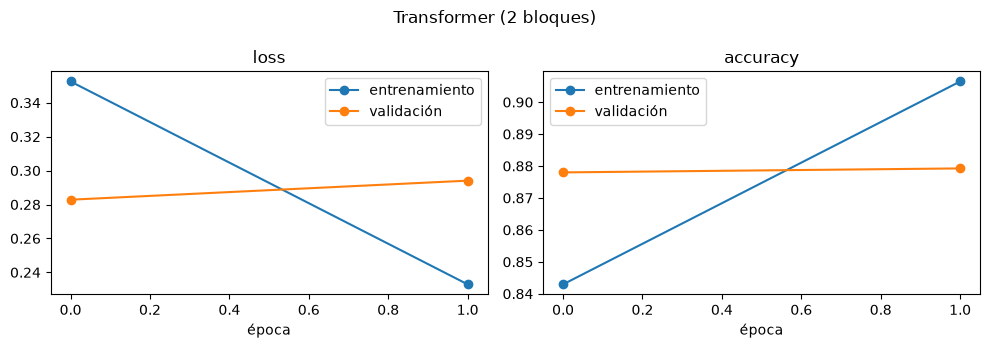

In [12]:
def graficar_historial(historial, titulo="Curvas de entrenamiento"):
    h = historial.history
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
    for ax, metrica in zip(axes, ["loss", "accuracy"]):
        ax.plot(h[metrica], marker="o", label="entrenamiento")
        ax.plot(h["val_" + metrica], marker="o", label="validación")
        ax.set_xlabel("época")
        ax.set_title(metrica)
        ax.legend()
    fig.suptitle(titulo)
    plt.tight_layout()
    plt.show()

def transformer_clasificador(n_bloques=2, d=64, cabezas=4, d_ff=128):
    entrada = keras.Input(shape=(LONGITUD,), dtype="int64")
    x = EmbeddingPosicional(LONGITUD, MAX_TOKENS, d, name="embedding")(entrada)
    for i in range(n_bloques):
        x = BloqueCodificador(d, cabezas, d_ff, name=f"bloque_{i}")(x)
    x = layers.GlobalAveragePooling1D()(x)
    x = layers.Dropout(0.3)(x)
    modelo = keras.Model(entrada, layers.Dense(1, activation="sigmoid")(x))
    modelo.compile(optimizer=keras.optimizers.Adam(5e-4), loss="binary_crossentropy", metrics=["accuracy"])
    return modelo


keras.utils.set_random_seed(SEED)
transformer = transformer_clasificador()
inicio = time.perf_counter()
historial = transformer.fit(
    X_train, y_train, validation_data=(X_val, y_val), epochs=6, batch_size=256, verbose=2,
    callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=1, restore_best_weights=True)])
print(f"Tiempo de entrenamiento: {time.perf_counter() - inicio:.0f} s | parámetros: {transformer.count_params():,}")
print(f"Exactitud en prueba: {transformer.evaluate(X_test, y_test, verbose=0)[1]:.4f}")
graficar_historial(historial, "Transformer (2 bloques)")

Resultados en prueba con los mismos datos, de los cuadernos anteriores:

| Modelo | Exactitud en prueba |
|---|---|
| Promedio de embeddings (cuaderno 13) | 0,888 |
| GRU (cuaderno 13) | 0,895 |
| LSTM bidireccional (cuaderno 13) | 0,898 |
| CNN (cuaderno 15) | 0,896–0,904 |

Un Transformer pequeño entrenado **desde cero** queda al nivel del promedio de embeddings y por debajo de las CNN y las RNN. No es una sorpresa: con 60 000 reseñas, los 1,3 millones de parámetros del embedding se aprenden solo a partir de la etiqueta de sentimiento, y las reseñas se clasifican bien con expresiones locales. La ventaja de los Transformers aparece cuando se **preentrenan** con miles de millones de palabras sin etiquetar y luego se ajustan a la tarea. Ese es el tema del cuaderno 17.

Veamos a qué palabras atienden las cabezas del primer bloque en una reseña. Llamamos directamente a la capa de atención con `return_attention_scores=True`:

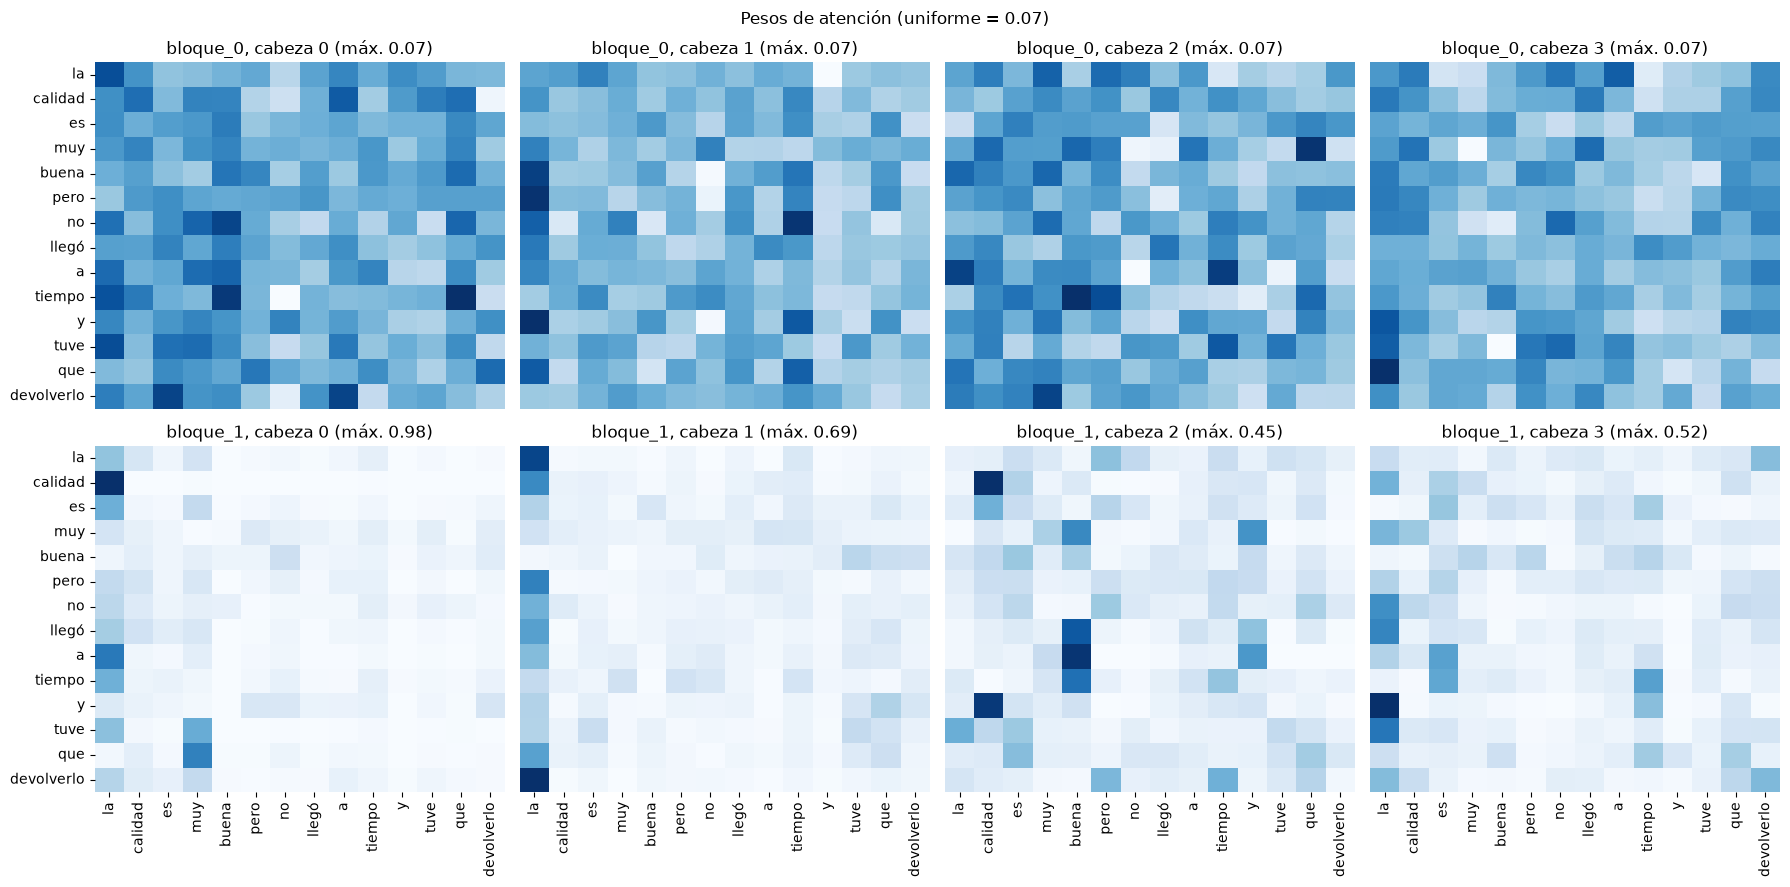

bloque_0: entropía relativa media en 300 reseñas de validación = 1.000


bloque_1: entropía relativa media en 300 reseñas de validación = 0.795


In [13]:
def pesos_atencion(texto, bloque="bloque_0"):
    ids = vectorizador(np.array([texto]))
    capa_emb = transformer.get_layer("embedding")
    x, mascara = capa_emb(ids), capa_emb.compute_mask(ids)
    for i in range(int(bloque.split("_")[1])):  # la entrada del bloque i es la salida del bloque i - 1
        x = transformer.get_layer(f"bloque_{i}")(x, mask=mascara)
    _, pesos = transformer.get_layer(bloque).atencion(x, x, attention_mask=mascara[:, None, :],
                                                      return_attention_scores=True)
    n = int(mascara.numpy().sum())
    return vocabulario[ids[0, :n].numpy()], pesos[0, :, :n, :n].numpy()  # (cabezas, n, n)


frase = "La calidad es muy buena pero no llegó a tiempo y tuve que devolverlo"
fig, axes = plt.subplots(2, 4, figsize=(18, 9))
for fila, bloque in enumerate(["bloque_0", "bloque_1"]):
    palabras, pesos = pesos_atencion(frase, bloque)
    for cabeza, ax in enumerate(axes[fila]):
        sns.heatmap(pesos[cabeza], xticklabels=palabras if fila == 1 else False,
                    yticklabels=palabras if cabeza == 0 else False, cmap="Blues", cbar=False, ax=ax)
        ax.set_title(f"{bloque}, cabeza {cabeza} (máx. {pesos[cabeza].max():.2f})")
plt.suptitle(f"Pesos de atención (uniforme = {1 / len(palabras):.2f})")
plt.tight_layout()
plt.show()


def entropia_relativa(bloque, textos):
    """Entropía media de las filas de atención dividida por la de una distribución uniforme (1 = uniforme)."""
    valores = []
    for texto in textos:
        _, pesos = pesos_atencion(texto, bloque)
        n = pesos.shape[-1]
        if n > 1:
            h = -(pesos * np.log(pesos + 1e-12)).sum(-1).mean()
            valores.append(h / np.log(n))
    return np.mean(valores)


for bloque in ["bloque_0", "bloque_1"]:
    print(f"{bloque}: entropía relativa media en 300 reseñas de validación = {entropia_relativa(bloque, X_val_txt[:300]):.3f}")

Los dos bloques se comportan de forma muy distinta:

- En el **primer bloque**, la atención es prácticamente **uniforme**: el peso máximo es 0,07, igual a $1/n$ para las 14 palabras, y la entropía relativa en 300 reseñas de validación es 1, el valor de una distribución uniforme. Cada palabra recibe el **promedio** de toda la reseña. Al inicio del entrenamiento los embeddings son pequeños y los puntajes $\mathbf{q} \cdot \mathbf{k}$ son casi cero, así que la atención empieza uniforme, y en esta tarea un promedio ya funciona bien, de modo que el gradiente casi no empuja a $W^Q$ y $W^K$ a especializarse. (Multiplicar los embeddings por $\sqrt{d}$, como en el artículo original, no cambia el resultado.)
- En el **segundo bloque**, las cabezas sí se especializan (entropía relativa de 0,8). Dos de ellas concentran casi toda la atención en la **primera palabra** de la reseña: es un patrón conocido en los Transformers, que usan un token fijo como "lugar de descanso" cuando no necesitan información de otra parte (en BERT suele ser `[CLS]` o `[SEP]`; Clark et al., 2019). Otra cabeza dirige la atención de varias palabras hacia *calidad* y *buena*, las palabras con carga de sentimiento.

Aun así, la exactitud es la misma que la del promedio de embeddings: la arquitectura permite relacionar palabras, pero los datos y la tarea determinan cuánto lo aprovecha el modelo. En los modelos preentrenados, predecir palabras enmascaradas **obliga** a relacionar palabras, y sus cabezas aprenden patrones sintácticos y de correferencia (Clark et al., 2019).

Hay que ser prudentes al interpretar estos mapas: los pesos de atención indican **de dónde** se mezcla información, no **qué palabras causan** la predicción (Jain & Wallace, 2019; Wiegreffe & Pinter, 2019). Volveremos sobre la explicabilidad en el cuaderno 19.

**Resumen del cuaderno:**

- La atención es un promedio ponderado de valores, con pesos dados por la similitud entre consultas y claves.
- La self-attention conecta directamente cada palabra con todas las demás y se calcula en paralelo, a un costo cuadrático en la longitud.
- Las múltiples cabezas permiten atender a varias relaciones a la vez; la codificación posicional aporta el orden.
- El bloque Transformer combina atención, una red feed-forward, conexiones residuales y normalización.
- Entrenado desde cero con pocos datos, un Transformer no supera a una CNN o una LSTM; en esta tarea su primer bloque ni siquiera aprendió a usar la atención. Su fortaleza es el **preentrenamiento a gran escala**.

<a id="referencias"></a>
<h2 style="color: #007ACC;">Referencias</h2>

- Jurafsky, D. & Martin, J. H. *Speech and Language Processing* (3.ª ed. borrador). [web.stanford.edu/~jurafsky/slp3](https://web.stanford.edu/~jurafsky/slp3/)
- Tunstall, L., von Werra, L. & Wolf, T. (2022). *Natural Language Processing with Transformers*. O'Reilly Media.
- Zhang, A., Lipton, Z. C., Li, M. & Smola, A. J. *Dive into Deep Learning*. [d2l.ai](https://d2l.ai/)
- Chollet, F. (2021). *Deep Learning with Python* (2.ª ed.). Manning.
- Bahdanau, D., Cho, K. & Bengio, Y. (2015). Neural Machine Translation by Jointly Learning to Align and Translate. *ICLR*.
- Vaswani, A. et al. (2017). Attention Is All You Need. *NeurIPS*.
- Alammar, J. (2018). The Illustrated Transformer. [jalammar.github.io](https://jalammar.github.io/illustrated-transformer/)
- Su, J. et al. (2021). RoFormer: Enhanced Transformer with Rotary Position Embedding. *arXiv:2104.09864*.
- Jain, S. & Wallace, B. C. (2019). Attention is not Explanation. *NAACL*.
- Clark, K., Khandelwal, U., Levy, O. & Manning, C. D. (2019). What Does BERT Look At? An Analysis of BERT's Attention. *BlackboxNLP*.
- Rothman, D. (2022). *Transformers for Natural Language Processing* (2.ª ed.). Packt.